# NumCompute-Stream Quickstart: Titanic survival

This notebook is a complete, runnable Titanic workflow using the local `demo/data/titanic.csv` file. It explores the data, trains a mixed-feature NumCompute-Stream decision-tree pipeline, evaluates it on held-out passengers, then demonstrates incremental test-then-train learning from CSV chunks. The charts use Matplotlib and the project visualization helpers.

The target is `survived` (`1` = survived). Predictors are passenger class, sex, age, family counts, fare, and embarkation port. The target-derived `alive` field and other redundant columns are intentionally excluded to prevent leakage. No download, Pandas, or scikit-learn is required.

In [1]:
from pathlib import Path
import sys
import time

%matplotlib inline
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np

project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'numcompute_stream').is_dir()
     and (path / 'demo' / 'data' / 'titanic.csv').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Open this notebook from the project or a subfolder of it.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from numcompute_stream import (
    AUC, Accuracy, ColumnSelector, Compose, ConfusionMatrix, DecisionTree, DecisionTreeClassifier,
    F1Score, FeatureUnion, Imputer, MinMaxScaler, OneHotEncoder, Pipeline,
    Precision, Recall, StandardScaler, StreamTrainer,
    StreamingHistogram, StreamingRanker, StreamingStats, StreamingTopK,
    accuracy, auc, benchmark, binary_search, compare_implementations,
    compare_models, confusion_matrix, cosine_similarity, deep_sizeof,
    euclidean_distance, f1, grad, histogram, iter_csv, jacobian, load_csv,
    manhattan_distance, multi_key_sort, precision, quickselect, rank, recall,
    roc_auc_score, roc_curve, stable_sort, stats_percentile, topk, update_stats,
)
from numcompute_stream.visualise import (
    compare_models, plot_metric_over_time, plot_predictions_vs_ground_truth,
)

DATA_PATH = project_root / 'demo' / 'data' / 'titanic.csv'
FEATURE_COLUMNS = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
print('Project:', project_root)
print('Titanic CSV:', DATA_PATH)

Project: C:\Users\mansi\Assignment 2.2\COMP-5004_Assignment-2.2
Titanic CSV: C:\Users\mansi\Assignment 2.2\COMP-5004_Assignment-2.2\demo\data\titanic.csv


## 1. Load the Titanic CSV

We start with the custom `load_csv` function from `numcompute_stream.io`. It reads the local Titanic file, checks that the expected columns exist, and separates the passenger predictors from the `survived` target. This whole-file read lets us inspect the data and later compare streaming results with a batch model. The streaming training section below reads the CSV again in bounded chunks.

In [109]:
header, passengers = load_csv(DATA_PATH, fill_value='NaN')
column_index = {name: index for index, name in enumerate(header)}
missing_columns = [name for name in [*FEATURE_COLUMNS, 'survived'] if name not in column_index]
if missing_columns:
    raise ValueError(f'Titanic CSV is missing required columns: {missing_columns}')

X = passengers[:, [column_index[name] for name in FEATURE_COLUMNS]]
y = passengers[:, column_index['survived']].astype(int)
age = passengers[:, column_index['age']].astype(float)
pclass = passengers[:, column_index['pclass']].astype(int)

print(f'Loaded {len(y)} passengers and {X.shape[1]} predictors.')
print('Predictors:', ', '.join(FEATURE_COLUMNS))
print('Survival labels:', dict(zip(*np.unique(y, return_counts=True))))
print('Missing age values:', int(np.isnan(age).sum()))
print('Missing embarkation values:', int(np.count_nonzero(passengers[:, column_index['embarked']] == 'NaN')))
print('First passenger:', {name: passengers[0, column_index[name]] for name in ['survived', 'pclass', 'sex', 'age', 'fare', 'embarked']})

Loaded 891 passengers and 7 predictors.
Predictors: pclass, sex, age, sibsp, parch, fare, embarked
Survival labels: {np.int64(0): np.int64(549), np.int64(1): np.int64(342)}
Missing age values: 177
Missing embarkation values: 2
First passenger: {'survived': 0.0, 'pclass': 3.0, 'sex': 'male', 'age': 22.0, 'fare': 7.25, 'embarked': 'S'}


## 2. Split the CSV stream into chunks

The custom `iter_csv` function from `numcompute_stream.io` yields one bounded chunk at a time. We set the chunk size here and preview the first chunk to show its feature and label shapes. The preview iterator is separate; the training step below opens a fresh iterator and processes every chunk in order, without storing the whole stream in memory.

In [3]:
CHUNK_SIZE = 96

def titanic_chunks():
    for chunk_header, rows in iter_csv(DATA_PATH, chunksize=CHUNK_SIZE, fill_value='NaN'):
        indices = [chunk_header.index(name) for name in FEATURE_COLUMNS]
        target_index = chunk_header.index('survived')
        yield rows[:, indices], rows[:, target_index].astype(int)

first_chunk_X, first_chunk_y = next(titanic_chunks())
print(f'Chunk size: {CHUNK_SIZE} rows maximum')
print(f'First chunk: X shape={first_chunk_X.shape}, y shape={first_chunk_y.shape}')

Chunk size: 96 rows maximum
First chunk: X shape=(96, 7), y shape=(96,)


## 3. Prepare the mixed-feature pipeline

We define the numeric and categorical preprocessing branches before training. Numeric values are imputed and standardized; categorical values are filled and one-hot encoded. The same pipeline structure is reused for incremental training and the batch comparison below.

In [4]:
def make_titanic_pipeline(buffer_size=None):
    features = FeatureUnion([
        ('numeric', Pipeline([
            ('select', ColumnSelector([0, 2, 3, 4, 5])),
            ('impute', Imputer(strategy='mean')),
            ('scale', StandardScaler()),
        ])),
        ('categorical', Pipeline([
            ('select', ColumnSelector([1, 6])),
            ('impute', Imputer(strategy='constant', fill_value='Unknown')),
            ('encode', OneHotEncoder(handle_unknown='ignore')),
        ])),
    ])
    tree_options = {'max_depth': 5, 'random_state': 7}
    if buffer_size is not None:
        tree_options['buffer_size'] = buffer_size
    return Pipeline([
        ('features', features),
        ('tree', DecisionTreeClassifier(**tree_options)),
    ])


## 4. Train the pipeline incrementally

`StreamTrainer.run` consumes the chunk iterator in order. The first chunk initializes the model; each later chunk is first scored with the previously trained model, then passed to `fit_chunk`. That update calls the pipeline's `.partial_fit()` on the current chunk, which updates its transformers and calls the decision tree's buffered `.partial_fit()`. The tree retrains when its sample buffer reaches the configured threshold. No full-stream training array is assembled.

In [5]:
stream_tree = DecisionTreeClassifier(max_depth=5, buffer_size=CHUNK_SIZE, random_state=7)
stream_pipeline = Pipeline([
    ('features', make_titanic_pipeline(buffer_size=CHUNK_SIZE).named_steps['features']),
    ('tree', stream_tree),
])
stream_trainer = StreamTrainer(stream_pipeline, track_memory=False)

stream_logs = stream_trainer.run(titanic_chunks())
scored_logs = [row for row in stream_logs if row['accuracy'] is not None]
print(f'Rows streamed: {sum(row["samples"] for row in stream_logs)}')
print(f'Chunks: {len(stream_logs)} | scored prequential chunks: {len(scored_logs)}')
print(f'Tree retraining events: {stream_tree.retraining_count_}')
print(f'Samples still buffered: {stream_tree.buffered_sample_count_}')
print(f'Cumulative prequential accuracy: {stream_logs[-1]["cumulative_accuracy"]:.3f}')
if scored_logs:
    print('First scored-chunk log:', scored_logs[0])

Rows streamed: 891
Chunks: 10 | scored prequential chunks: 9
Tree retraining events: 9
Samples still buffered: 27
Cumulative prequential accuracy: 0.743
First scored-chunk log: {'chunk': 1, 'samples': 96, 'accuracy': 0.71875, 'cumulative_accuracy': 0.71875, 'score_seconds': 0.003987499978393316, 'memory_bytes': None}


## 5. Log and visualize streaming performance

`StreamTrainer` records chunk-level accuracy and cumulative accuracy as it processes the stream. The plots below use `plot_metric_over_time` from `numcompute_stream.visualise` to show how each metric changes over time. Chunk accuracy can vary from one group of passengers to another, while cumulative accuracy summarizes all scored chunks so far.

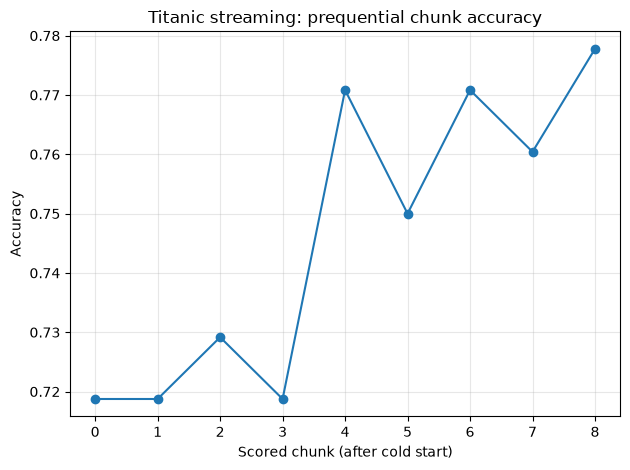

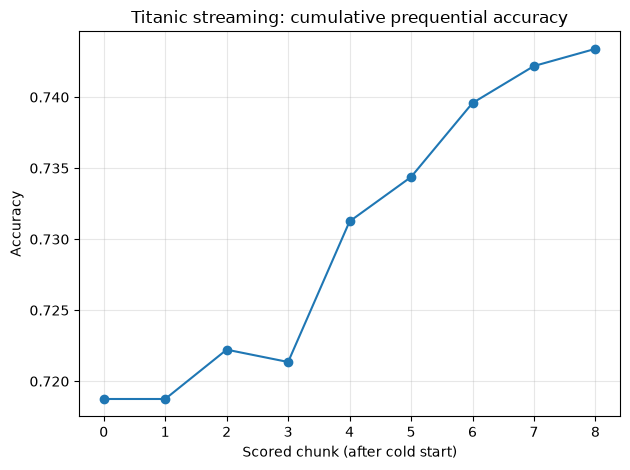

In [6]:
chunk_accuracy = stream_trainer.metric_history('accuracy')
cumulative_accuracy = stream_trainer.metric_history('cumulative_accuracy')
fig, ax = plot_metric_over_time(
    chunk_accuracy,
    title='Titanic streaming: prequential chunk accuracy',
    ylabel='Accuracy',
)
ax.set_xlabel('Scored chunk (after cold start)')
display(fig)
plt.close(fig)

fig, ax = plot_metric_over_time(
    cumulative_accuracy,
    title='Titanic streaming: cumulative prequential accuracy',
    ylabel='Accuracy',
)
ax.set_xlabel('Scored chunk (after cold start)')
display(fig)
plt.close(fig)

## 6. Explore the passenger data

Now that the incremental workflow is complete, these plots give a little context about the data being modeled. Missing ages are excluded from the histogram, and survival rates are calculated directly from the labels for each passenger class.

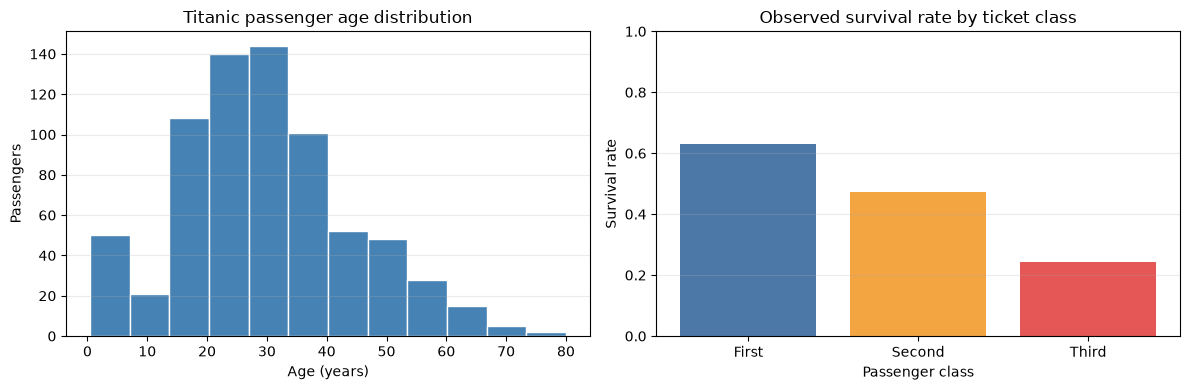

Age histogram contains 714 passengers with recorded age.


In [7]:
known_age = age[np.isfinite(age)]
age_counts, age_edges = np.histogram(known_age, bins=12)
survival_rate_by_class = [float(np.mean(y[pclass == cls])) for cls in (1, 2, 3)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(known_age, bins=age_edges, color='steelblue', edgecolor='white')
axes[0].set(title='Titanic passenger age distribution', xlabel='Age (years)', ylabel='Passengers')
axes[0].grid(axis='y', alpha=0.25)
axes[1].bar(['First', 'Second', 'Third'], survival_rate_by_class, color=['#4c78a8', '#f2a541', '#e45756'])
axes[1].set(title='Observed survival rate by ticket class', xlabel='Passenger class', ylabel='Survival rate', ylim=(0, 1))
axes[1].grid(axis='y', alpha=0.25)
fig.tight_layout()
display(fig)
plt.close(fig)
print(f'Age histogram contains {age_counts.sum()} passengers with recorded age.')

## 7. Compare with a batch-trained decision tree

As a reference point, we fit the same mixed-feature pipeline in one batch. A seeded split keeps the held-out passengers separate from training. The following cells report classification metrics and show the learned model and its predictions; this is a batch comparison, distinct from the chunk-by-chunk training above.

In [8]:
rng = np.random.default_rng(42)
permutation = rng.permutation(len(y))
n_test = int(np.ceil(0.2 * len(y)))
test_indices, train_indices = permutation[:n_test], permutation[n_test:]
batch_model = make_titanic_pipeline()
batch_model.fit(X[train_indices], y[train_indices])
batch_predictions = batch_model.predict(X[test_indices])
batch_accuracy = accuracy(y[test_indices], batch_predictions)
batch_matrix = confusion_matrix(y[test_indices], batch_predictions, labels=[0, 1])

print(f'Train passengers: {len(train_indices)} | held-out passengers: {len(test_indices)}')


Train passengers: 712 | held-out passengers: 179


### Batch model results and learned tree

The held-out results include accuracy, precision, recall, F1, and ROC AUC. We also inspect the tree's learned state and visualize its structure. The following cell adds an annotated confusion matrix and a small sample of predictions.

DecisionTreeClassifier / DecisionTree alias: DecisionTreeClassifier
Classes: [0, 1] | accuracy=0.793 | precision=0.831 | recall=0.675 | F1=0.745 | ROC AUC=0.849
Tree config/state: criterion=gini, max_depth=5, max_features=None, fitted=True, depth=5, leaves=23, nodes=45, retrains=1, buffered=0
First 8 held-out actual / predicted / P(survived):
  1 / 0 / 0.000
  1 / 1 / 0.989
  0 / 0 / 0.082
  1 / 0 / 0.330
  0 / 0 / 0.330
  0 / 0 / 0.082
  1 / 1 / 0.989
  0 / 0 / 0.082
Configured streaming tree: criterion=entropy, max_features=sqrt, retrains=1
Prediction before fitting is rejected: DecisionTreeClassifier is not fitted; call fit or buffer enough samples with partial_fit.


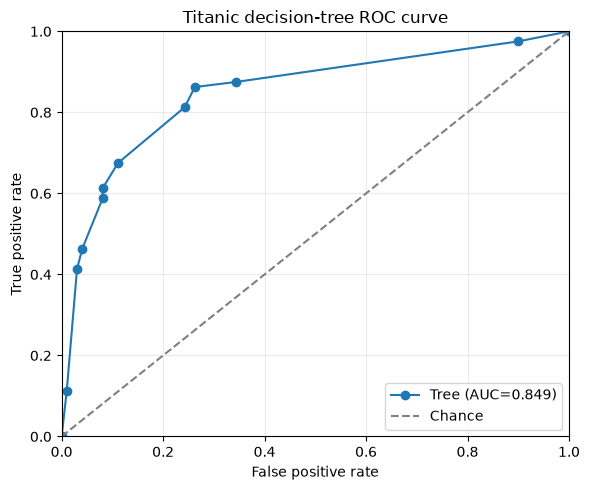

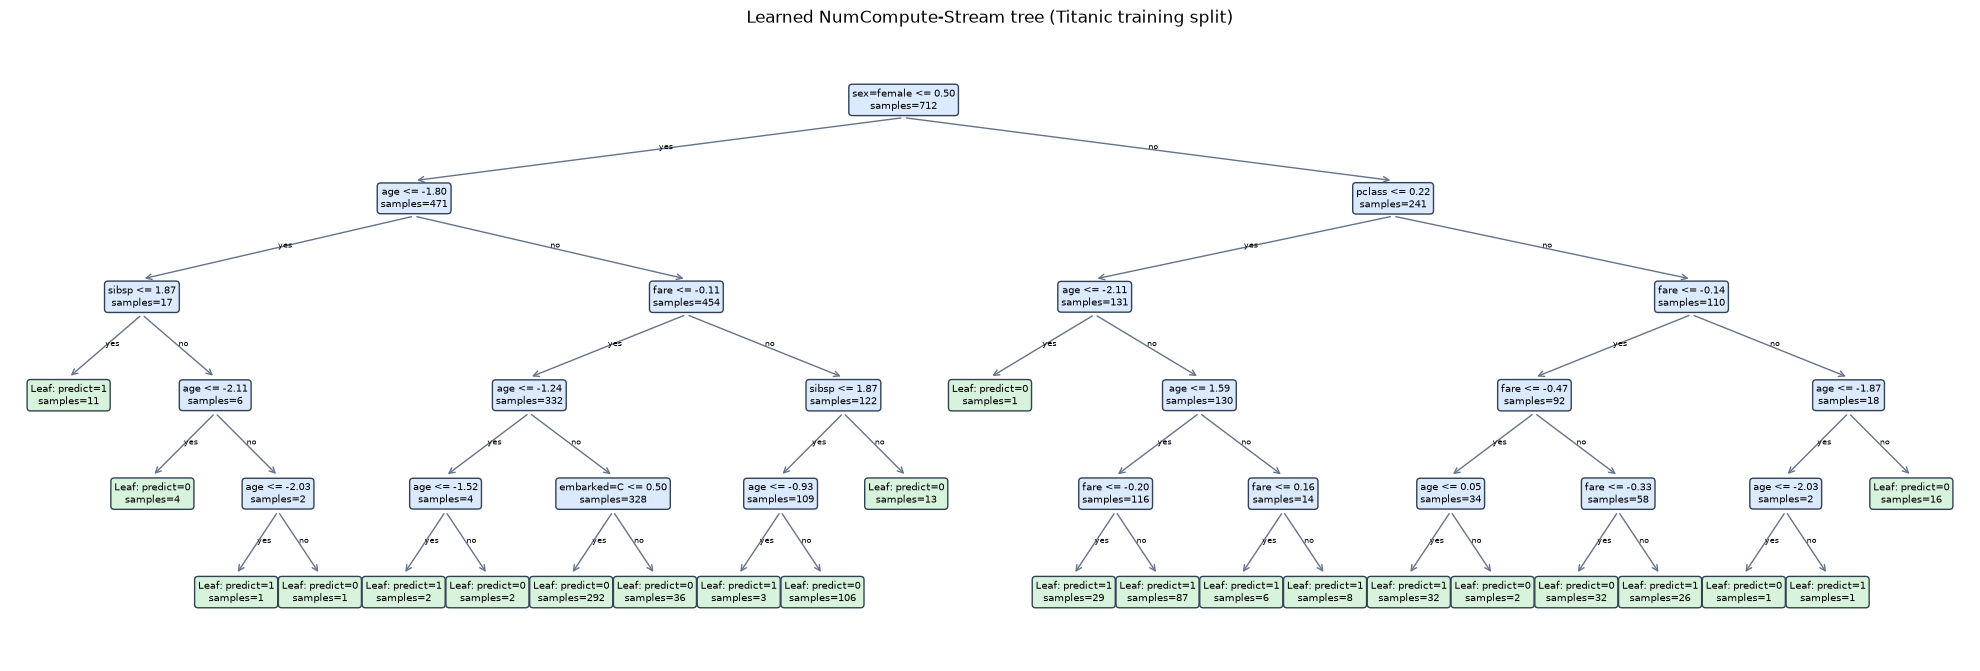

In [9]:
batch_tree = batch_model.named_steps['tree']
batch_probabilities = batch_model.predict_proba(X[test_indices])
positive_column = int(np.flatnonzero(batch_tree.classes_ == 1)[0])
positive_scores = batch_probabilities[:, positive_column]
batch_precision = precision(y[test_indices], batch_predictions)
batch_recall = recall(y[test_indices], batch_predictions)
batch_f1 = f1(y[test_indices], batch_predictions)
batch_auc = roc_auc_score(y[test_indices], positive_scores, positive_label=1)
false_positive_rate, true_positive_rate, _ = roc_curve(y[test_indices], positive_scores, positive_label=1)
print('DecisionTreeClassifier / DecisionTree alias:', type(batch_tree).__name__)
print(f'Classes: {batch_tree.classes_.tolist()} | accuracy={batch_accuracy:.3f} | precision={batch_precision:.3f} | recall={batch_recall:.3f} | F1={batch_f1:.3f} | ROC AUC={batch_auc:.3f}')
print(f"Tree config/state: criterion={batch_tree.criterion}, max_depth={batch_tree.max_depth}, max_features={batch_tree.max_features}, fitted={batch_tree.is_fitted_}, depth={batch_tree.depth_}, leaves={batch_tree.n_leaves_}, nodes={len(batch_tree.nodes_)}, retrains={batch_tree.retraining_count_}, buffered={batch_tree.buffered_sample_count_}")
print('First 8 held-out actual / predicted / P(survived):')
for actual, predicted, probability in zip(y[test_indices][:8], batch_predictions[:8], positive_scores[:8]):
    print(f'  {actual} / {predicted} / {probability:.3f}')
entropy_example = DecisionTree(max_depth=3, min_samples_split=4, max_features='sqrt', buffer_size=96, criterion='entropy', random_state=11)
entropy_example.partial_fit(batch_model.named_steps['features'].transform(X[train_indices][:96]), y[train_indices][:96])
print(f'Configured streaming tree: criterion={entropy_example.criterion}, max_features={entropy_example.max_features}, retrains={entropy_example.retraining_count_}')
unfitted_tree = DecisionTree(max_depth=1)
try:
    unfitted_tree.predict([[0.0]])
except ValueError as error:
    print('Prediction before fitting is rejected:', error)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(false_positive_rate, true_positive_rate, marker='o', label=f'Tree (AUC={batch_auc:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
ax.set(title='Titanic decision-tree ROC curve', xlabel='False positive rate', ylabel='True positive rate', xlim=(0, 1), ylim=(0, 1))
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
display(fig)
plt.close(fig)

numeric_names = ['pclass', 'age', 'sibsp', 'parch', 'fare']
categorical_branch = dict(batch_model.named_steps['features'].transformer_list)['categorical']
categorical_encoder = categorical_branch.named_steps['encode']
split_feature_names = numeric_names + [
    f'{name}={category}'
    for name, categories in zip(['sex', 'embarked'], categorical_encoder.categories_)
    for category in categories
]
tree_positions = {}
leaf_x = [0]
def place_tree_node(index):
    node = batch_tree.nodes_[index]
    if node['leaf']:
        x_position = leaf_x[0]
        leaf_x[0] += 1
    else:
        left_x = place_tree_node(node['left'])
        right_x = place_tree_node(node['right'])
        x_position = (left_x + right_x) / 2
    tree_positions[index] = (x_position, -node['depth'])
    return x_position
place_tree_node(0)
fig, ax = plt.subplots(figsize=(20, 7))
for index, node in enumerate(batch_tree.nodes_):
    x_position, y_position = tree_positions[index]
    if node['leaf']:
        label = f"Leaf: predict={batch_tree.classes_[node['prediction']]}\nsamples={int(node['counts'].sum())}"
        color = '#d8f3dc'
    else:
        label = f"{split_feature_names[node['feature']]} <= {node['threshold']:.2f}\nsamples={int(node['counts'].sum())}"
        color = '#dbeafe'
    ax.text(x_position, y_position, label, ha='center', va='center', fontsize=7, bbox={'boxstyle': 'round,pad=0.35', 'facecolor': color, 'edgecolor': '#334155'})
    if not node['leaf']:
        for child_key, branch_label in [('left', 'yes'), ('right', 'no')]:
            child = node[child_key]
            child_x, child_y = tree_positions[child]
            ax.annotate('', xy=(child_x, child_y + 0.18), xytext=(x_position, y_position - 0.18), arrowprops={'arrowstyle': '->', 'color': '#64748b'})
            ax.text((x_position + child_x) / 2, (y_position + child_y) / 2, branch_label, fontsize=6)
ax.set_xlim(-0.7, leaf_x[0] - 0.3)
ax.set_ylim(-batch_tree.depth_ - 0.7, 0.7)
ax.set_title('Learned NumCompute-Stream tree (Titanic training split)')
ax.set_axis_off()
fig.subplots_adjust(left=0.01, right=0.99, top=0.92, bottom=0.02)
display(fig)
plt.close(fig)

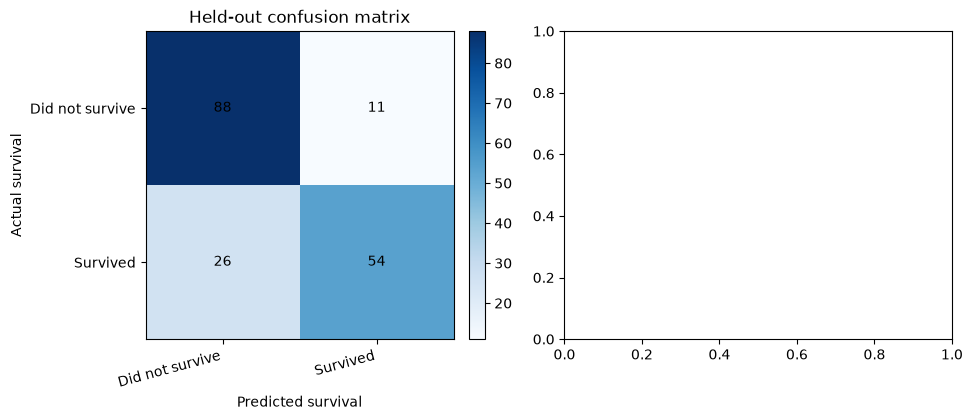

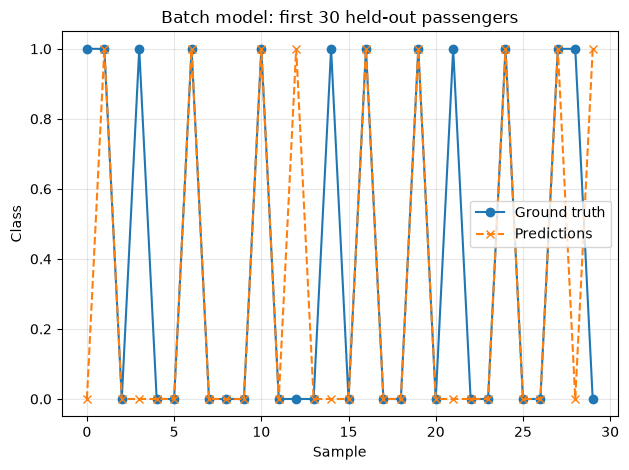

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
image = axes[0].imshow(batch_matrix, cmap='Blues')
axes[0].set(title='Held-out confusion matrix', xlabel='Predicted survival', ylabel='Actual survival', xticks=[0, 1], yticks=[0, 1])
axes[0].set_xticklabels(['Did not survive', 'Survived'], rotation=15, ha='right')
axes[0].set_yticklabels(['Did not survive', 'Survived'])
for row in range(2):
    for col in range(2):
        axes[0].text(col, row, str(batch_matrix[row, col]), ha='center', va='center')
fig.colorbar(image, ax=axes[0], fraction=0.046, pad=0.04)
display(fig)
prediction_fig, _ = plot_predictions_vs_ground_truth(
    y[test_indices][:30], batch_predictions[:30],
    title='Batch model: first 30 held-out passengers',
)
display(prediction_fig)
plt.close(fig)
plt.close(prediction_fig)

## 8. Update descriptive statistics by chunk

The recorded passenger ages are fed to `StreamingStats` and `StreamingHistogram` in several chunks. The summary and histogram demonstrate incremental updates independently of model training.

Streaming age summary: {'count': 714, 'mean': 29.699117647058824, 'variance': 210.72357975366617, 'std': 14.516321150817316, 'min': 0.42, 'max': 80.0}
Histogram observations: 714


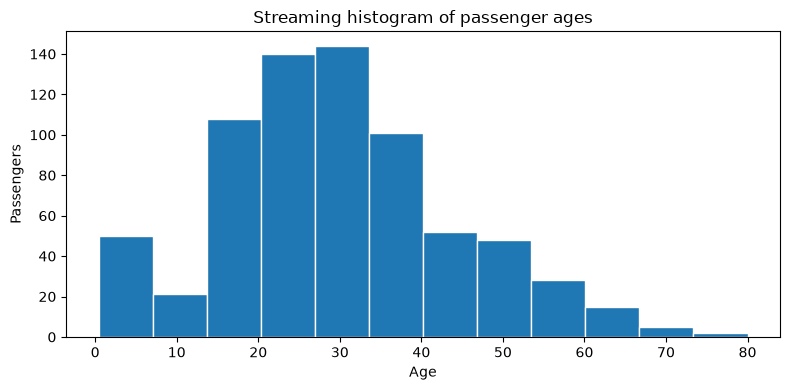

In [11]:
age_stats = StreamingStats()
age_histogram = StreamingHistogram(bins=12)
for age_chunk in np.array_split(known_age, 6):
    age_stats.update(age_chunk)
    age_histogram.update(age_chunk)

age_summary = age_stats.result()
age_counts_stream, age_edges_stream = age_histogram.result()
print('Streaming age summary:', age_summary)
print('Histogram observations:', int(age_counts_stream.sum()))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(age_edges_stream[:-1], age_counts_stream, width=np.diff(age_edges_stream), align='edge', edgecolor='white')
ax.set(title='Streaming histogram of passenger ages', xlabel='Age', ylabel='Passengers')
plt.tight_layout()
display(fig)
plt.close(fig)

## 9. Explore preprocessing APIs

This section demonstrates batch and incremental scaling, imputation, column selection, composition, and category learning. When the one-hot encoder learns additional categories, it appends their columns so the meanings of existing columns remain stable.

In [12]:
numeric_columns = [0, 2, 3, 4, 5]
numeric_raw = X[:, numeric_columns].astype(float)
numeric_filled = Imputer(strategy='median').fit_transform(numeric_raw)

incremental_scaler = StandardScaler()
incremental_scaler.partial_fit(numeric_filled[:300])
incremental_scaler.partial_fit(numeric_filled[300:600])
incremental_scaler.partial_fit(numeric_filled[600:])
scaled_preview = incremental_scaler.transform(numeric_filled[:5])
minmax = MinMaxScaler(clip=True).partial_fit(numeric_filled[:300])
minmax.partial_fit(numeric_filled[300:])
selected_preview = ColumnSelector([0, 2]).fit_transform(X[:5])

category_encoder = OneHotEncoder(handle_unknown='ignore')
first_category_chunk = X[:1, [1, 6]]
category_encoder.partial_fit(first_category_chunk)
original_categories = [values.copy() for values in category_encoder.categories_]
category_encoder.partial_fit(X[1:40, [1, 6]])
assert all(np.array_equal(before, after[:before.size]) for before, after in zip(original_categories, category_encoder.categories_))
encoded_preview = category_encoder.transform(X[:5, [1, 6]])

composed = Compose([
    ('impute', Imputer(strategy='median')),
    ('scale', StandardScaler()),
])
composed.partial_fit(numeric_raw[:200])
composed.partial_fit(numeric_raw[200:400])
constant_output = StandardScaler().partial_fit(np.ones(4)).transform(np.ones(2))
print('Scaler learned samples/features:', incremental_scaler.n_samples_seen_, incremental_scaler.mean_.size)
print('StandardScaler preview shape:', scaled_preview.shape, '| clipped MinMax preview:', minmax.transform(numeric_filled[:2]).round(3).tolist())
print('Selector output shape:', selected_preview.shape, '| composed output shape:', composed.transform(numeric_raw[:5]).shape)
print('OneHotEncoder category counts before/after:', [len(values) for values in original_categories], [len(values) for values in category_encoder.categories_])
print('OneHotEncoder output shape:', encoded_preview.shape, '| constant-feature output:', constant_output.tolist())

Scaler learned samples/features: 891 5
StandardScaler preview shape: (5, 5) | clipped MinMax preview: [[1.0, 0.271, 0.125, 0.0, 0.014], [0.0, 0.472, 0.125, 0.0, 0.139]]
Selector output shape: (5, 2) | composed output shape: (5, 5)
OneHotEncoder category counts before/after: [1, 1] [2, 3]
OneHotEncoder output shape: (5, 5) | constant-feature output: [0.0, 0.0]


## 10. Explore streaming metrics and numerical utilities

We compare batch metrics with incremental metric updates on the same held-out predictions. Streaming AUC uses bounded-memory score bins, so it is an approximation to exact batch ROC AUC. The examples also cover ranking, sorting, search, statistics, distances, and finite-difference derivatives.

In [13]:
metric_objects = {
    'accuracy': Accuracy(),
    'precision': Precision(positive_label=1),
    'recall': Recall(positive_label=1),
    'f1': F1Score(positive_label=1),
    'rolling_accuracy_64': Accuracy(window=64),
    'confusion_matrix': ConfusionMatrix(labels=[0, 1]),
}
stream_auc = AUC(n_bins=128, positive_label=1)
for start in range(0, len(test_indices), 48):
    stop = start + 48
    truth_chunk = y[test_indices][start:stop]
    prediction_chunk = batch_predictions[start:stop]
    score_chunk = positive_scores[start:stop]
    for metric in metric_objects.values():
        metric.update(truth_chunk, prediction_chunk)
    stream_auc.update(truth_chunk, score_chunk)
print('Streaming metrics:', {name: metric.result() for name, metric in metric_objects.items() if name != 'confusion_matrix'})
print('Streaming confusion matrix:\n', metric_objects['confusion_matrix'].result())
print(f'Binned streaming AUC: {stream_auc.result():.3f} | exact batch ROC AUC: {batch_auc:.3f}')

ranker = StreamingRanker(method='average').update(known_age[:200]).update(known_age[200:])
top_fares = StreamingTopK(5).update(numeric_filled[:400, 4]).update(numeric_filled[400:, 4])
sorted_ages = stable_sort(known_age)
binary_position, age_found = binary_search(sorted_ages, 22.0)
print('Top streamed fares:', top_fares.result()[0].tolist())
print('Age rank sample:', ranker.result()[:8].tolist(), '| top-k ages:', topk(known_age, 3, largest=True, return_indices=False).tolist())
print('Quickselect median age:', quickselect(known_age, (len(known_age) + 1) // 2), '| binary search age 22:', age_found, 'at', binary_position)
print('Multi-key passenger order (first 10):', multi_key_sort([pclass[:10], y[:10]]).tolist())
print('Age median / 90th percentile:', float(np.median(known_age)), stats_percentile(known_age, 90))

stats_state = update_stats(known_age[:300])
stats_state = update_stats(known_age[300:], stats_state)
one_bin = StreamingHistogram(bins=1).update([7.0, 7.0, 7.0])
print('Merged age-stat count/mean:', stats_state['count'], round(stats_state['mean'], 3))
print('One-bin histogram counts/edges:', one_bin.result()[0].tolist(), one_bin.result()[1].tolist())
print('Distances:', round(euclidean_distance([1, 2], [2, 4]), 3), round(manhattan_distance([1, 2], [2, 4]), 3), round(cosine_similarity([1, 2], [2, 4]), 3))
print('Large-magnitude derivative:', grad(lambda value: value * value, 1e12))
print('Jacobian at [2, 3]:\n', jacobian(lambda value: [value[0] + value[1], value[0] * value[1]], [2.0, 3.0]))
print('Approximate batch pipeline memory (bytes):', deep_sizeof(batch_model))

Streaming metrics: {'accuracy': 0.7932960893854749, 'precision': 0.8307692307692308, 'recall': 0.675, 'f1': 0.7448275862068966, 'rolling_accuracy_64': 0.78125}
Streaming confusion matrix:
 [[88 11]
 [26 54]]
Binned streaming AUC: 0.849 | exact batch ROC AUC: 0.849
Top streamed fares: [512.3292, 512.3292, 512.3292, 263.0, 263.0]
Age rank sample: [218.0, 532.0, 310.5, 488.5, 488.5, 668.5, 19.5, 328.5] | top-k ages: [71.0, 74.0, 80.0]
Quickselect median age: 28.0 | binary search age 22: True at 204
Multi-key passenger order (first 10): [6, 1, 3, 9, 0, 4, 5, 7, 2, 8]
Age median / 90th percentile: 28.0 50.0
Merged age-stat count/mean: 714 29.699
One-bin histogram counts/edges: [3] [6.999999999999999, 7.000000000000002]
Distances: 2.236 3.0 1.0
Large-magnitude derivative: 2199023255552.0
Jacobian at [2, 3]:
 [[1. 1.]
 [3. 2.]]
Approximate batch pipeline memory (bytes): 139309


## 11. Compare vectorized performance and tree buffer sizes

The first benchmark checks that loop-based and NumPy-vectorized implementations return the same results before timing them. The second runs streaming tree experiments with different buffer sizes and compares prequential accuracy, retraining counts, and retraining time.

Loop vs vectorized timing summaries (seconds): {'Python loop': 0.000924, 'NumPy vectorized': 7e-06}
Benchmark environment: {'python': '3.14.7', 'numpy': '2.5.2', 'platform': 'Windows-11-10.0.26200-SP0'}


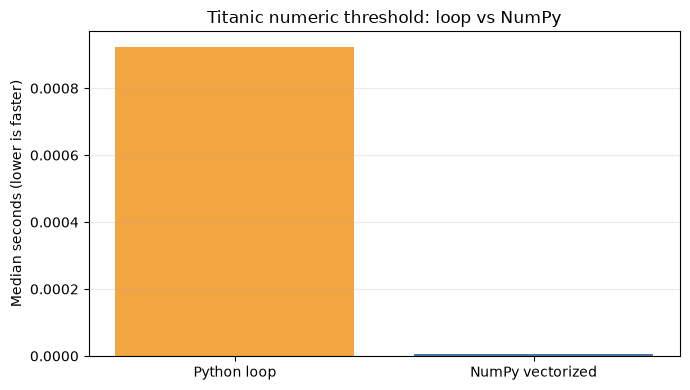

buffer_size=48: prequential accuracy=0.673, retrains=18, retraining-call time=0.0455s, pending=27
buffer_size=96: prequential accuracy=0.648, retrains=9, retraining-call time=0.0302s, pending=27
buffer_size=192: prequential accuracy=0.664, retrains=4, retraining-call time=0.0137s, pending=123


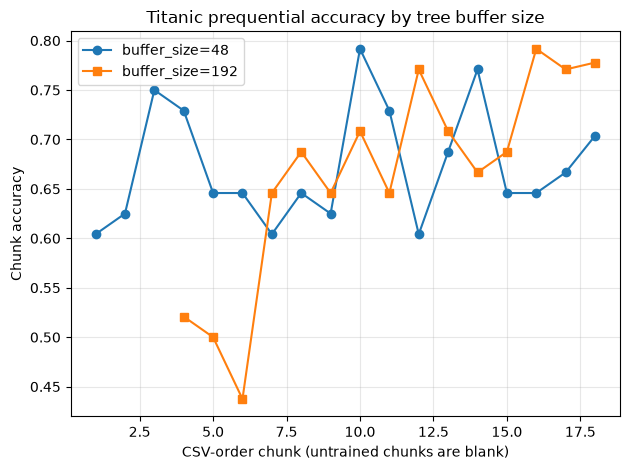

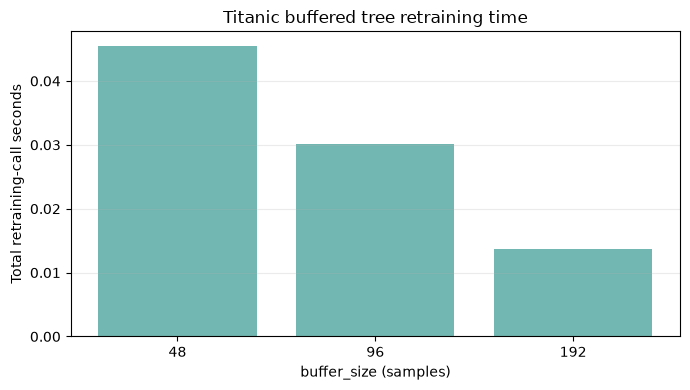

In [14]:
def loop_threshold_predict(values, threshold):
    predictions = np.empty(values.shape[0], dtype=np.int64)
    for row_index in range(values.shape[0]):
        total = 0.0
        for column_index in range(values.shape[1]):
            total += values[row_index, column_index]
        predictions[row_index] = total > threshold
    return predictions

def vectorized_threshold_predict(values, threshold):
    return (values.sum(axis=1) > threshold).astype(np.int64)

threshold = float(np.mean(numeric_filled.sum(axis=1)))
implementation_timings = compare_implementations(
    {'Python loop': loop_threshold_predict, 'NumPy vectorized': vectorized_threshold_predict},
    numeric_filled, threshold, reference='Python loop', repeats=5, warmup=1,
)
vectorized_benchmark = benchmark(vectorized_threshold_predict, numeric_filled, threshold, repeats=5, warmup=1)
print('Loop vs vectorized timing summaries (seconds):', {name: round(result['median_seconds'], 6) for name, result in implementation_timings.items()})
print('Benchmark environment:', vectorized_benchmark['environment'])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(list(implementation_timings), [result['median_seconds'] for result in implementation_timings.values()], color=['#f2a541', '#4c78a8'])
ax.set(title='Titanic numeric threshold: loop vs NumPy', ylabel='Median seconds (lower is faster)')
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
display(fig)
plt.close(fig)

benchmark_numeric = Imputer(strategy='median').fit(numeric_raw[:48]).transform(numeric_raw)
def run_buffer_experiment(buffer_size, chunk_size=48):
    model = DecisionTree(max_depth=4, buffer_size=buffer_size, random_state=11)
    accuracy_by_chunk = []
    retraining_seconds = 0.0
    for start in range(0, len(y), chunk_size):
        X_chunk = benchmark_numeric[start:start + chunk_size]
        y_chunk = y[start:start + chunk_size]
        accuracy_by_chunk.append(accuracy(y_chunk, model.predict(X_chunk)) if model.is_fitted_ else np.nan)
        previous_retrains = model.retraining_count_
        started = time.perf_counter()
        model.partial_fit(X_chunk, y_chunk)
        elapsed = time.perf_counter() - started
        if model.retraining_count_ > previous_retrains:
            retraining_seconds += elapsed
    return {
        'accuracy_by_chunk': np.asarray(accuracy_by_chunk),
        'prequential_accuracy': float(np.nanmean(accuracy_by_chunk)),
        'retraining_count': model.retraining_count_,
        'retraining_seconds': retraining_seconds,
        'buffered_samples': model.buffered_sample_count_,
    }

buffer_sizes = [48, 96, 192]
buffer_results = {size: run_buffer_experiment(size) for size in buffer_sizes}
for size, result in buffer_results.items():
    print(f"buffer_size={size}: prequential accuracy={result['prequential_accuracy']:.3f}, retrains={result['retraining_count']}, retraining-call time={result['retraining_seconds']:.4f}s, pending={result['buffered_samples']}")

fig, ax = compare_models(
    buffer_results[48]['accuracy_by_chunk'],
    buffer_results[192]['accuracy_by_chunk'],
    labels=['buffer_size=48', 'buffer_size=192'],
    title='Titanic prequential accuracy by tree buffer size',
    ylabel='Chunk accuracy',
)
ax.set_xlabel('CSV-order chunk (untrained chunks are blank)')
display(fig)
plt.close(fig)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([str(size) for size in buffer_sizes], [buffer_results[size]['retraining_seconds'] for size in buffer_sizes], color='#72b7b2')
ax.set(title='Titanic buffered tree retraining time', xlabel='buffer_size (samples)', ylabel='Total retraining-call seconds')
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
display(fig)
plt.close(fig)

## Project coverage and supporting files

The workflow above follows the assignment's main streaming path: load the Titanic CSV with the custom I/O module, read it in chunks, train through `.partial_fit()`, and log and visualize metrics. The remaining sections demonstrate additional package features, comparisons, benchmarks, and the complete specification coverage.

| Assignment requirement | Demonstration / implementation |
|---|---|
| NumPy vectorized numerical and ML operations | NumPy preprocessing, metrics, and vectorized benchmark in this notebook |
| Chunked CSV IO and bounded streaming | `iter_csv` and `StreamTrainer.run` on the local Titanic CSV |
| Buffered tree retraining | `DecisionTreeClassifier` / `DecisionTree`; counts, state, and buffer-size experiment |
| Preprocessing and pipeline incrementality | Imputer, both scalers, encoder, selector, `Compose`, `FeatureUnion`, `Pipeline.partial_fit` |
| Numerical stability, shape and NaN handling | Titanic missing values, constant-feature scaling, incremental moments, finite differences |
| Sorting, search, ranking and statistics | Batch and streaming calls, including a one-bin histogram |
| Batch and streaming classification metrics | Classification metrics, rolling accuracy, confusion matrix, exact and binned AUC |
| Streaming visualization | Chunk/cumulative metric trends, prediction-vs-truth, tree, confusion matrix, and buffer comparison |
| Benchmarking | Correctness-checked loop/vectorized timing and retraining measurements for three buffer sizes |
| Tests and documentation | At least 30 unit tests; see `tests/`, `README.md`, and `NUMCOMPUTE_STREAM.md` |

Source modules: [`numcompute_stream/__init__.py`](../numcompute_stream/__init__.py), [`io.py`](../numcompute_stream/io.py), [`preprocessing.py`](../numcompute_stream/preprocessing.py), [`sort_search.py`](../numcompute_stream/sort_search.py), [`rank.py`](../numcompute_stream/rank.py), [`stats.py`](../numcompute_stream/stats.py), [`metrics.py`](../numcompute_stream/metrics.py), [`optim.py`](../numcompute_stream/optim.py), [`pipeline.py`](../numcompute_stream/pipeline.py), [`tree.py`](../numcompute_stream/tree.py), [`stream.py`](../numcompute_stream/stream.py), [`visualise.py`](../numcompute_stream/visualise.py), [`benchmarking.py`](../numcompute_stream/benchmarking.py), [`utils.py`](../numcompute_stream/utils.py), and [`_validation.py`](../numcompute_stream/_validation.py).

Companion deliverables: [`demo/stream_demo.ipynb`](stream_demo.ipynb), [`demo/train_titanic.py`](train_titanic.py), [`benchmark/vectorized_vs_loop.py`](../benchmark/vectorized_vs_loop.py), [`tests/`](../tests/), [`README.md`](../README.md), [`NUMCOMPUTE_STREAM.md`](../NUMCOMPUTE_STREAM.md), and [`Assignment2.2-specs.md`](../Assignment2.2-specs.md). Timing varies by machine; `StreamingHistogram` and exact `StreamingRanker` retain observations (O(n) memory without a window), while streaming AUC is bounded-memory and approximate.

Run the notebook from top to bottom. Timing results vary by environment; model scores are tied to the included Titanic data and deterministic model settings.